# 📊 Visualisasi Pengujian Sistem Notulensi Rapat

Notebook ini menampilkan visualisasi hasil pengujian seluruh fitur sistem secara komprehensif:

1. **Whisper Transcription Accuracy** — WER, WAcc, CER per topik
2. **Noise Reduction Filter** — Perbandingan sebelum & sesudah
3. **Word Filler Removal** — Confusion Matrix & Precision/Recall/F1
4. **Hallucination Filter** — Performa per kondisi pengujian
5. **Hybrid Extractive LexRank** — Cosine Sim, Jaccard, Coverage, Compression
6. **Ollama Abstractive Summarization** — BERTScore Precision/Recall/F1

---

In [1]:
# ── Instalasi & Import ─────────────────────────────────────────
import subprocess, sys
def install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

for pkg in ['matplotlib', 'numpy', 'seaborn', 'pandas']:
    install(pkg)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ── Style global ───────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

# Palet warna konsisten
BLUE   = '#2196F3'
GREEN  = '#4CAF50'
ORANGE = '#FF9800'
RED    = '#F44336'
PURPLE = '#9C27B0'
TEAL   = '#009688'
BEFORE_COLOR = '#EF5350'
AFTER_COLOR  = '#42A5F5'

print('✅ Library berhasil dimuat!')

✅ Library berhasil dimuat!


---
## 1️⃣ Pengujian Akurasi Whisper Transcription

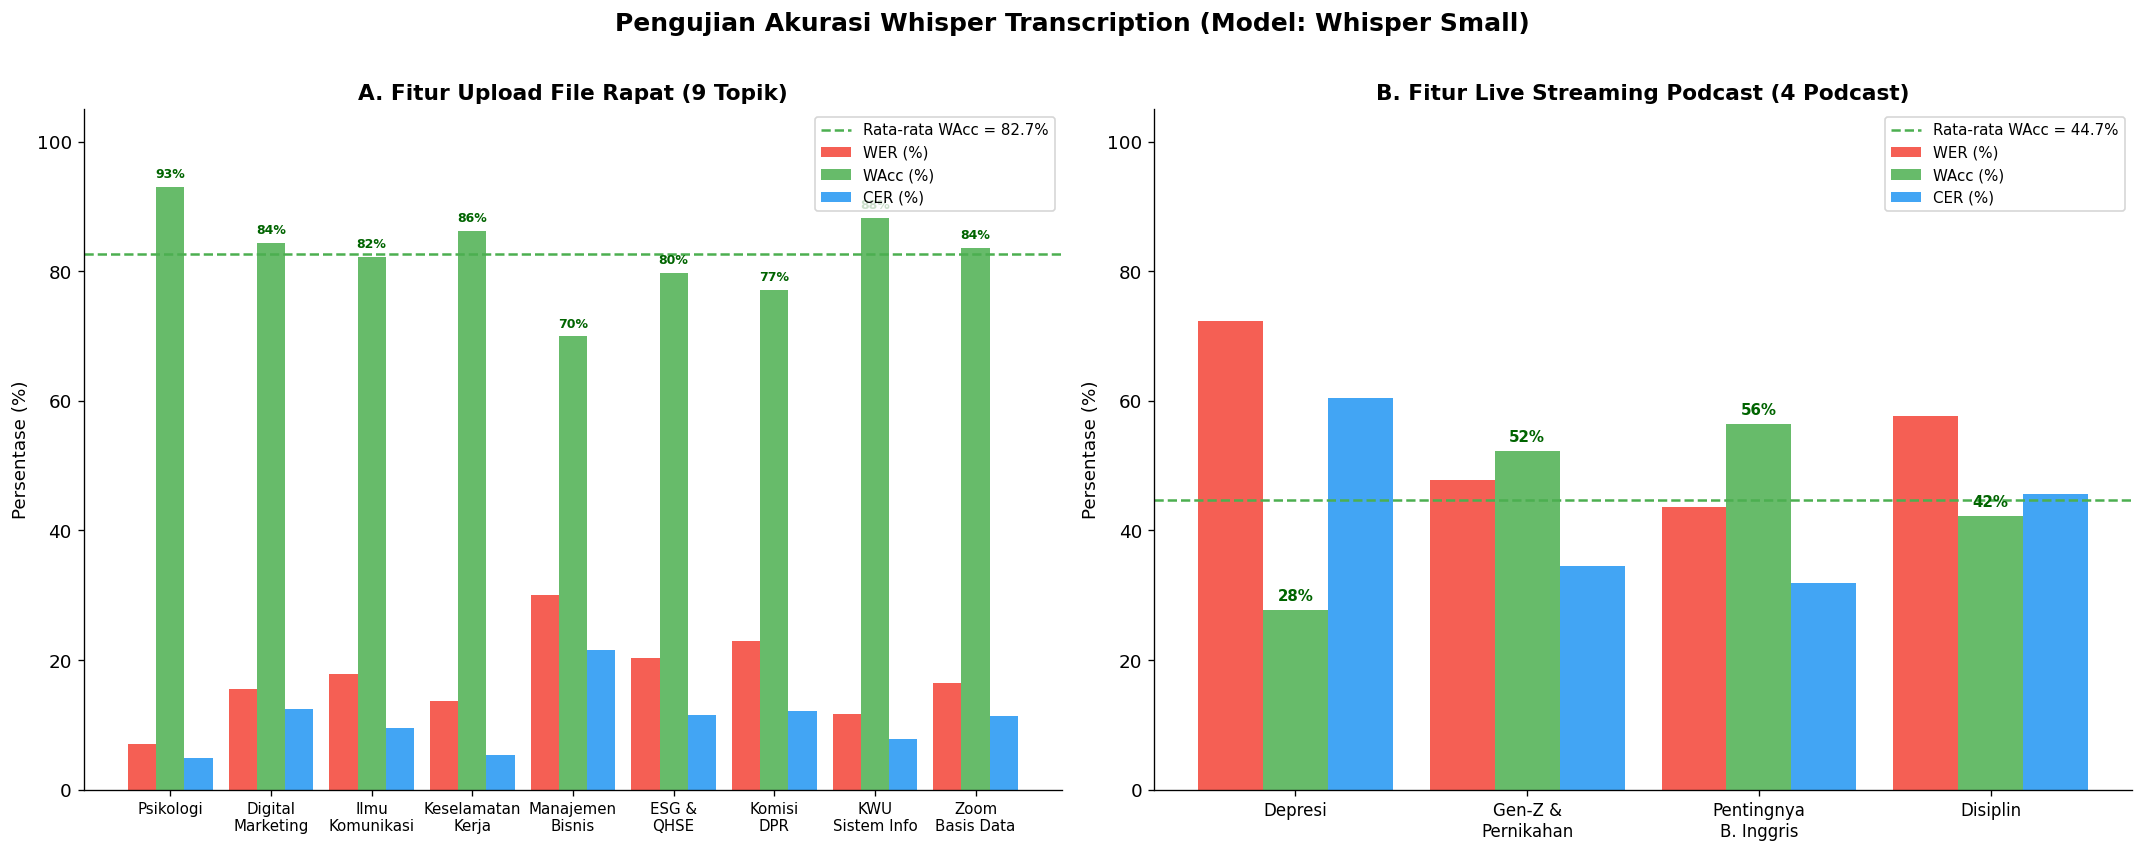


📌 Rata-rata WAcc Upload : 82.74%
📌 Rata-rata WAcc Live   : 44.68%


In [2]:
# ── DATA: Whisper Upload (9 Rapat) ─────────────────────────────
topik_upload = [
    'Psikologi', 'Digital\nMarketing', 'Ilmu\nKomunikasi',
    'Keselamatan\nKerja', 'Manajemen\nBisnis', 'ESG &\nQHSE',
    'Komisi\nDPR', 'KWU\nSistem Info', 'Zoom\nBasis Data'
]
wer_upload  = [6.96, 15.57, 17.82, 13.72, 30.05, 20.26, 22.91, 11.72, 16.37]
wacc_upload = [93.04, 84.43, 82.18, 86.28, 69.95, 79.74, 77.09, 88.28, 83.63]
cer_upload  = [4.89, 12.39, 9.49, 5.27, 21.50, 11.57, 12.12, 7.80, 11.34]

# ── DATA: Live Podcast (4 Podcast) ─────────────────────────────
topik_live = ['Depresi', 'Gen-Z &\nPernikahan', 'Pentingnya\nB. Inggris', 'Disiplin']
wer_live   = [72.29, 47.71, 43.57, 57.72]
wacc_live  = [27.71, 52.29, 56.43, 42.28]
cer_live   = [60.42, 34.46, 31.86, 45.68]

# ── PLOT ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Pengujian Akurasi Whisper Transcription (Model: Whisper Small)',
             fontsize=15, fontweight='bold', y=1.01)

x1 = np.arange(len(topik_upload))
x2 = np.arange(len(topik_live))
bw = 0.28

# --- Panel A: Upload ---
ax = axes[0]
b1 = ax.bar(x1 - bw, wer_upload,  bw, label='WER (%)',  color=RED,   alpha=0.85)
b2 = ax.bar(x1,       wacc_upload, bw, label='WAcc (%)', color=GREEN, alpha=0.85)
b3 = ax.bar(x1 + bw,  cer_upload,  bw, label='CER (%)',  color=BLUE,  alpha=0.85)
ax.axhline(y=np.mean(wacc_upload), color=GREEN, linestyle='--', linewidth=1.5,
           label=f'Rata-rata WAcc = {np.mean(wacc_upload):.1f}%')
ax.set_title('A. Fitur Upload File Rapat (9 Topik)')
ax.set_xticks(x1)
ax.set_xticklabels(topik_upload, fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel('Persentase (%)')
ax.legend(fontsize=9)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=7.5, color='darkgreen', fontweight='bold')

# --- Panel B: Live ---
ax2 = axes[1]
b4 = ax2.bar(x2 - bw, wer_live,  bw, label='WER (%)',  color=RED,   alpha=0.85)
b5 = ax2.bar(x2,       wacc_live, bw, label='WAcc (%)', color=GREEN, alpha=0.85)
b6 = ax2.bar(x2 + bw,  cer_live,  bw, label='CER (%)',  color=BLUE,  alpha=0.85)
ax2.axhline(y=np.mean(wacc_live), color=GREEN, linestyle='--', linewidth=1.5,
            label=f'Rata-rata WAcc = {np.mean(wacc_live):.1f}%')
ax2.set_title('B. Fitur Live Streaming Podcast (4 Podcast)')
ax2.set_xticks(x2)
ax2.set_xticklabels(topik_live, fontsize=10)
ax2.set_ylim(0, 105)
ax2.set_ylabel('Persentase (%)')
ax2.legend(fontsize=9)
for bar in b5:
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=9, color='darkgreen', fontweight='bold')

plt.tight_layout()
plt.savefig('../visual uji/1_whisper_accuracy.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'\n📌 Rata-rata WAcc Upload : {np.mean(wacc_upload):.2f}%')
print(f'📌 Rata-rata WAcc Live   : {np.mean(wacc_live):.2f}%')

---
## 2️⃣ Pengujian Noise Reduction Filter

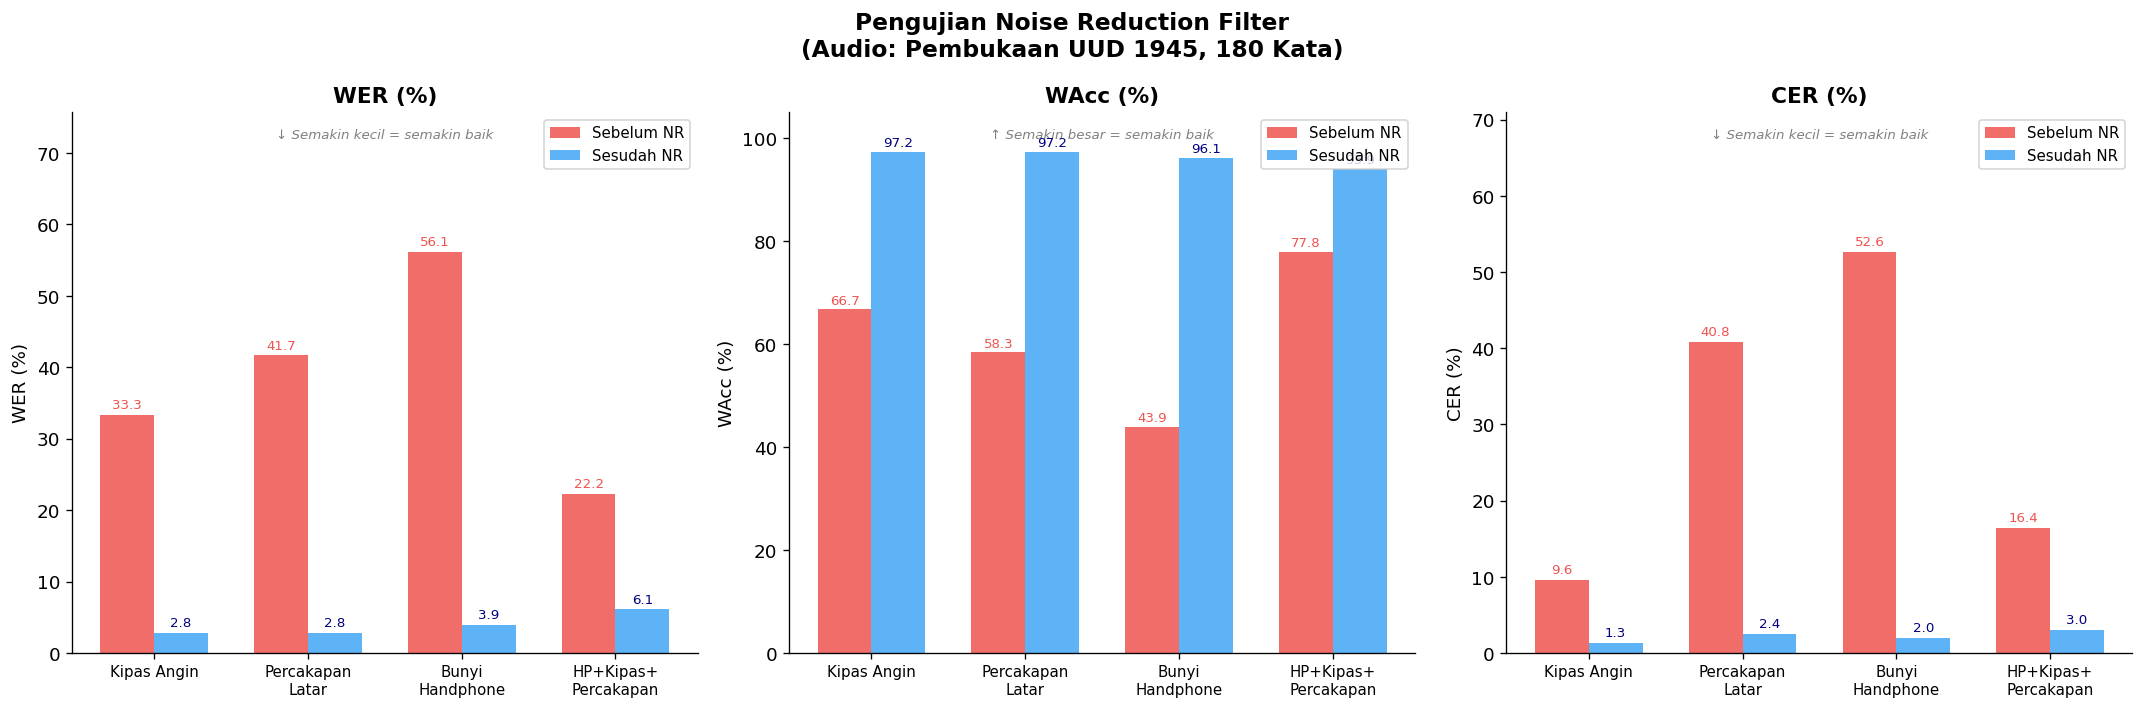


📌 RINGKASAN NOISE REDUCTION:
   WER  : 38.33% → 3.89%  (↓ 34.44%)
   WAcc : 61.67% → 96.11%  (↑ 34.44%)
   CER  : 29.83% → 2.19%  (↓ 27.64%)


In [3]:
# ── DATA: Noise Reduction ──────────────────────────────────────
noise_labels  = ['Kipas Angin', 'Percakapan\nLatar', 'Bunyi\nHandphone', 'HP+Kipas+\nPercakapan']

wer_before  = [33.33, 41.67, 56.11, 22.22]
wer_after   = [2.78,  2.78,  3.89,  6.11]
wacc_before = [66.67, 58.33, 43.89, 77.78]
wacc_after  = [97.22, 97.22, 96.11, 93.89]
cer_before  = [9.55,  40.80, 52.59, 16.38]
cer_after   = [1.29,  2.44,  2.01,  3.02]

x = np.arange(len(noise_labels))
bw = 0.35

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Pengujian Noise Reduction Filter\n(Audio: Pembukaan UUD 1945, 180 Kata)',
             fontsize=14, fontweight='bold')

metrics = [
    ('WER (%)',  wer_before,  wer_after,  axes[0], '↓ Semakin kecil = semakin baik'),
    ('WAcc (%)', wacc_before, wacc_after, axes[1], '↑ Semakin besar = semakin baik'),
    ('CER (%)',  cer_before,  cer_after,  axes[2], '↓ Semakin kecil = semakin baik'),
]

for (label, before, after, ax, hint) in metrics:
    b1 = ax.bar(x - bw/2, before, bw, label='Sebelum NR', color=BEFORE_COLOR, alpha=0.85)
    b2 = ax.bar(x + bw/2, after,  bw, label='Sesudah NR', color=AFTER_COLOR,  alpha=0.85)
    ax.set_title(label)
    ax.set_xticks(x)
    ax.set_xticklabels(noise_labels, fontsize=9)
    ax.set_ylabel(label)
    ax.set_ylim(0, max(before) * 1.35)
    ax.legend(fontsize=9)
    ax.text(0.5, 0.97, hint, transform=ax.transAxes, ha='center', va='top',
            fontsize=8, color='gray', style='italic')
    for bar in b1:
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.5,
                f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8, color=BEFORE_COLOR)
    for bar in b2:
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.5,
                f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8, color='navy')

plt.tight_layout()
plt.savefig('../visual uji/2_noise_reduction.png', bbox_inches='tight', dpi=150)
plt.show()

# -- Ringkasan --
print('\n📌 RINGKASAN NOISE REDUCTION:')
print(f'   WER  : {np.mean(wer_before):.2f}% → {np.mean(wer_after):.2f}%  (↓ {np.mean(wer_before)-np.mean(wer_after):.2f}%)')
print(f'   WAcc : {np.mean(wacc_before):.2f}% → {np.mean(wacc_after):.2f}%  (↑ {np.mean(wacc_after)-np.mean(wacc_before):.2f}%)')
print(f'   CER  : {np.mean(cer_before):.2f}% → {np.mean(cer_after):.2f}%  (↓ {np.mean(cer_before)-np.mean(cer_after):.2f}%)')

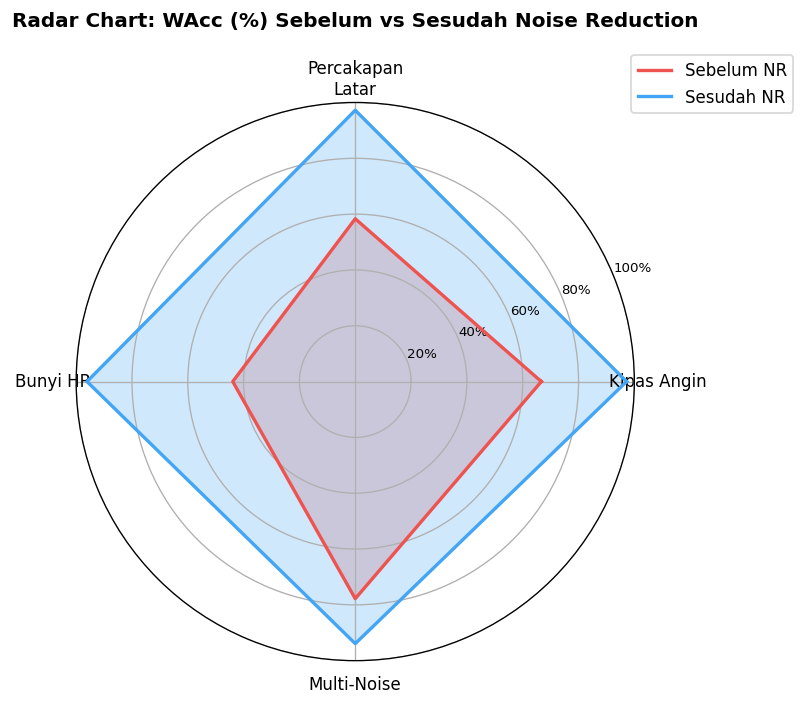

In [4]:
# ── Radar Chart: Perbandingan per Kondisi Noise ────────────────
categories = ['Kipas Angin', 'Percakapan\nLatar', 'Bunyi HP', 'Multi-Noise']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

wacc_b = wacc_before + [wacc_before[0]]
wacc_a = wacc_after  + [wacc_after[0]]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.fill(angles, wacc_b, color=BEFORE_COLOR, alpha=0.25)
ax.plot(angles, wacc_b, color=BEFORE_COLOR, linewidth=2, label='Sebelum NR')
ax.fill(angles, wacc_a, color=AFTER_COLOR, alpha=0.25)
ax.plot(angles, wacc_a, color=AFTER_COLOR, linewidth=2, label='Sesudah NR')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_yticklabels(['20%','40%','60%','80%','100%'], fontsize=8)
ax.set_title('Radar Chart: WAcc (%) Sebelum vs Sesudah Noise Reduction',
             fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.tight_layout()
plt.savefig('../visual uji/2b_noise_radar.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 3️⃣ Pengujian Word Filler Removal

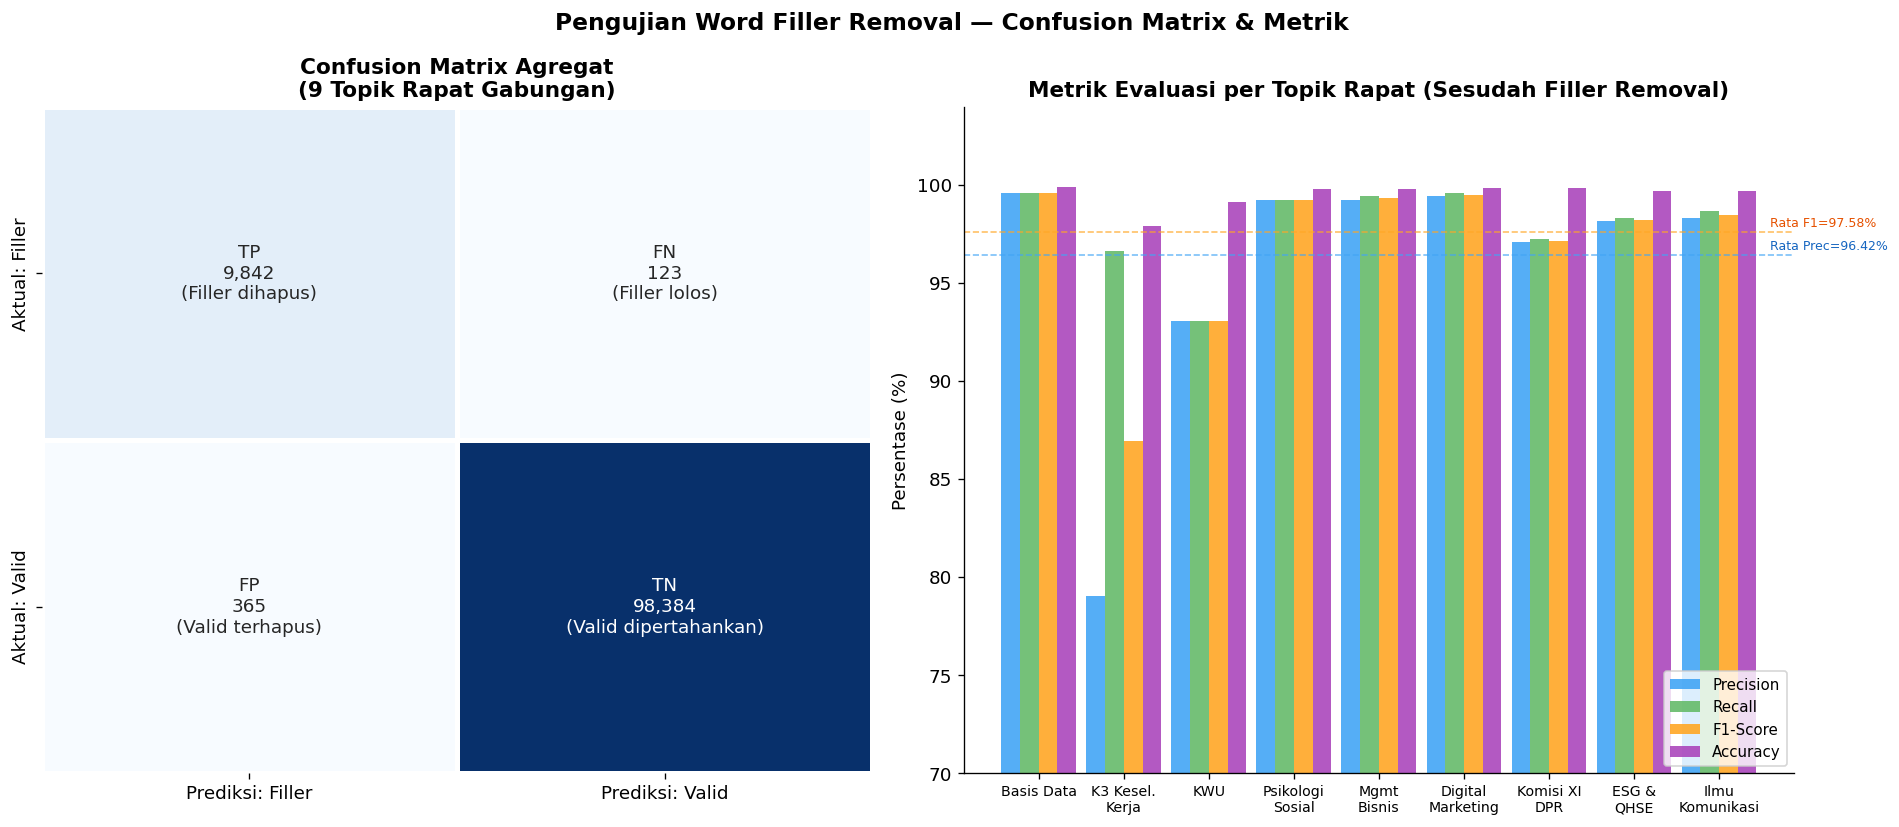


📌 RINGKASAN WORD FILLER REMOVAL:
   Rata-rata Precision : 95.91%
   Rata-rata Recall    : 97.97%
   Rata-rata F1-Score  : 96.84%
   Rata-rata Accuracy  : 99.52%


In [5]:
# ── DATA: Word Filler Removal ──────────────────────────────────
topik_filler = [
    'Basis Data', 'K3 Kesel.\nKerja', 'KWU',
    'Psikologi\nSosial', 'Mgmt\nBisnis', 'Digital\nMarketing',
    'Komisi XI\nDPR', 'ESG &\nQHSE', 'Ilmu\nKomunikasi'
]
tp = [1696, 999, 134, 537, 520, 3210, 668, 693, 1385]
fp = [7, 265, 10, 4, 4, 18, 20, 13, 24]
fn = [7, 35, 10, 4, 3, 14, 19, 12, 19]
tn = [10089, 13133, 2142, 3621, 3211, 17959, 26257, 8194, 13778]

prec_after = [99.59, 79.03, 93.06, 99.26, 99.24, 99.44, 97.09, 98.16, 98.30]
rec_after  = [99.59, 96.62, 93.06, 99.26, 99.43, 99.57, 97.23, 98.30, 98.65]
f1_after   = [99.59, 86.95, 93.06, 99.26, 99.33, 99.50, 97.16, 98.23, 98.47]
acc_after  = [99.88, 97.92, 99.13, 99.81, 99.81, 99.85, 99.86, 99.72, 99.72]

# --- Confusion Matrix Agregat ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Pengujian Word Filler Removal — Confusion Matrix & Metrik', fontsize=14, fontweight='bold')

# Heatmap confusion matrix agregat
ax = axes[0]
total_tp = sum(tp); total_fp = sum(fp); total_fn = sum(fn); total_tn = sum(tn)
cm = np.array([[total_tp, total_fn], [total_fp, total_tn]])
cm_labels = np.array([
    [f'TP\n{total_tp:,}\n(Filler dihapus)', f'FN\n{total_fn:,}\n(Filler lolos)'],
    [f'FP\n{total_fp:,}\n(Valid terhapus)', f'TN\n{total_tn:,}\n(Valid dipertahankan)']
])
sns.heatmap(cm, annot=cm_labels, fmt='', cmap='Blues', ax=ax,
            xticklabels=['Prediksi: Filler', 'Prediksi: Valid'],
            yticklabels=['Aktual: Filler', 'Aktual: Valid'],
            linewidths=2, linecolor='white', cbar=False, annot_kws={'size': 11})
ax.set_title('Confusion Matrix Agregat\n(9 Topik Rapat Gabungan)')

# Bar chart metrik per topik
ax2 = axes[1]
x = np.arange(len(topik_filler))
bw = 0.22
ax2.bar(x - bw*1.5, prec_after, bw, label='Precision',  color='#42A5F5', alpha=0.9)
ax2.bar(x - bw*0.5, rec_after,  bw, label='Recall',     color='#66BB6A', alpha=0.9)
ax2.bar(x + bw*0.5, f1_after,   bw, label='F1-Score',   color='#FFA726', alpha=0.9)
ax2.bar(x + bw*1.5, acc_after,  bw, label='Accuracy',   color='#AB47BC', alpha=0.9)
ax2.set_title('Metrik Evaluasi per Topik Rapat (Sesudah Filler Removal)')
ax2.set_xticks(x)
ax2.set_xticklabels(topik_filler, fontsize=8.5)
ax2.set_ylim(70, 104)
ax2.set_ylabel('Persentase (%)')
ax2.axhline(96.42, color='#42A5F5', linestyle='--', linewidth=1, alpha=0.7)
ax2.axhline(97.58, color='#FFA726', linestyle='--', linewidth=1, alpha=0.7)
ax2.legend(fontsize=9, loc='lower right')
ax2.text(8.6, 96.42+0.3, f'Rata Prec={96.42}%', fontsize=7.5, color='#1565C0')
ax2.text(8.6, 97.58+0.3, f'Rata F1={97.58}%', fontsize=7.5, color='#E65100')

plt.tight_layout()
plt.savefig('../visual uji/3_word_filler_removal.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n📌 RINGKASAN WORD FILLER REMOVAL:')
print(f'   Rata-rata Precision : {np.mean(prec_after):.2f}%')
print(f'   Rata-rata Recall    : {np.mean(rec_after):.2f}%')
print(f'   Rata-rata F1-Score  : {np.mean(f1_after):.2f}%')
print(f'   Rata-rata Accuracy  : {np.mean(acc_after):.2f}%')

---
## 4️⃣ Pengujian Hallucination Filter

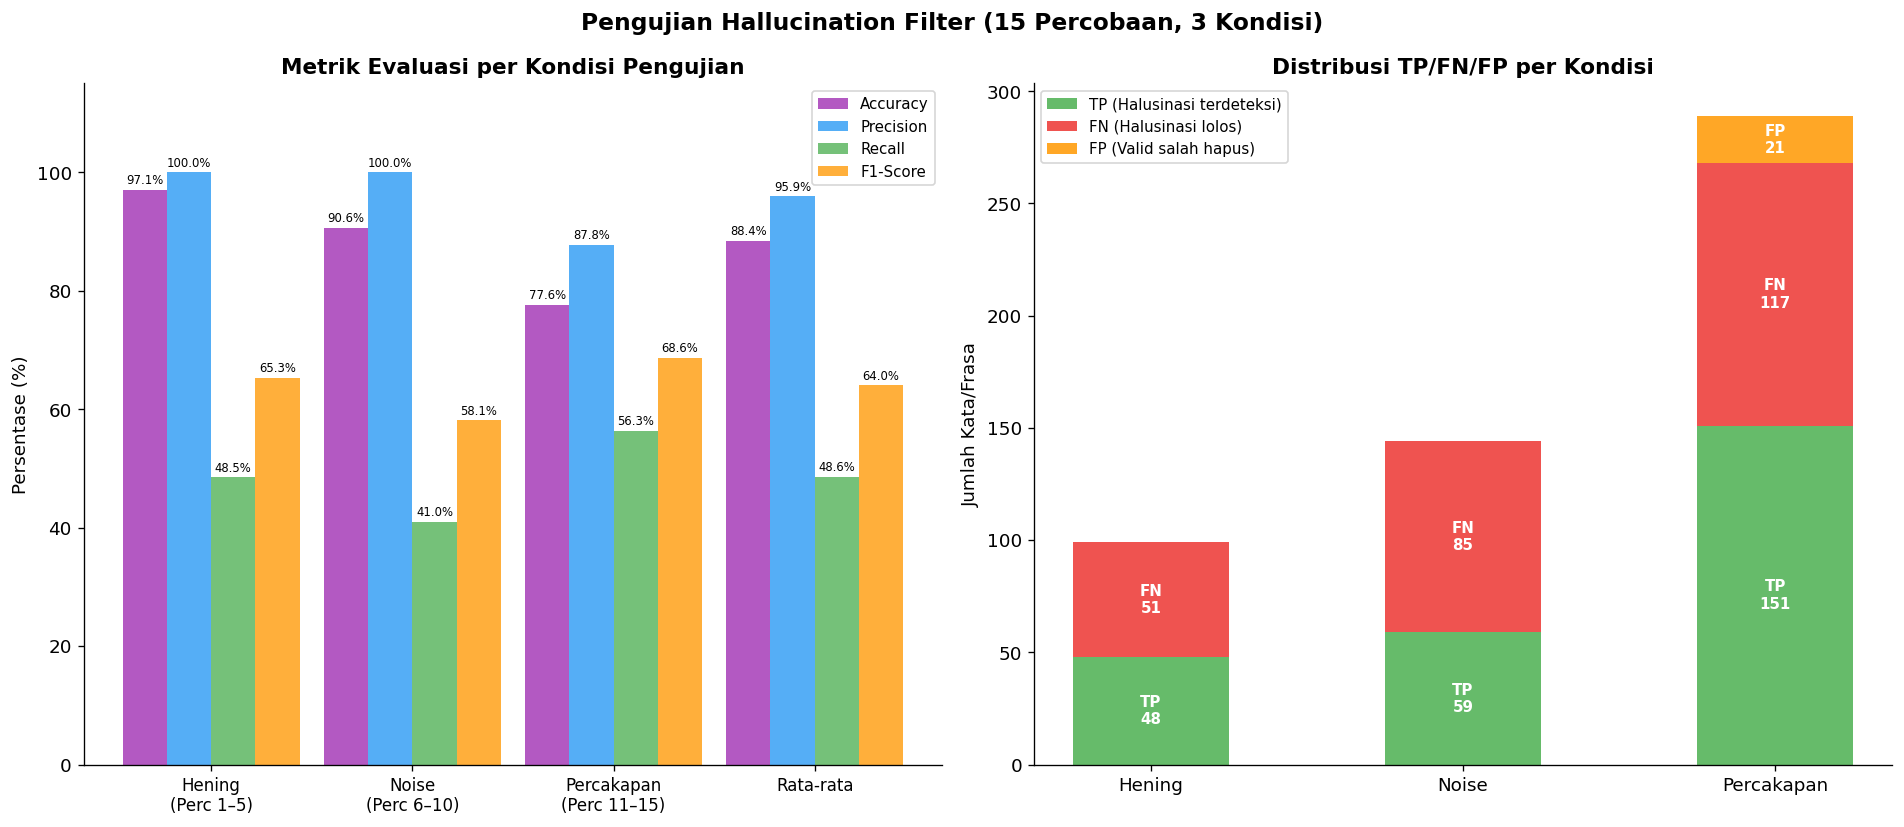


📌 RINGKASAN HALLUCINATION FILTER:
   Rata-rata Precision : 95.93%  (FP sangat rendah)
   Rata-rata Recall    : 48.60%  (masih bisa ditingkatkan)
   Rata-rata F1-Score  : 64.03%
   Rata-rata Accuracy  : 88.42%


In [6]:
# ── DATA: Hallucination Filter ─────────────────────────────────
kondisi = ['Hening\n(Perc 1–5)', 'Noise\n(Perc 6–10)', 'Percakapan\n(Perc 11–15)', 'Rata-rata']
tp_h  = [48,  59,  151, 86]
fp_h  = [0,   0,   21,  7]
fn_h  = [51,  85,  117, 84]
tn_h  = [1639,760, 327, 909]
acc_h = [97.07, 90.60, 77.60, 88.42]
prec_h= [100.0, 100.0, 87.79, 95.93]
rec_h = [48.48, 40.97, 56.34, 48.60]
f1_h  = [65.31, 58.13, 68.64, 64.03]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Pengujian Hallucination Filter (15 Percobaan, 3 Kondisi)',
             fontsize=14, fontweight='bold')

# --- Panel kiri: Grouped bar metrik ---
ax = axes[0]
x = np.arange(len(kondisi))
bw = 0.22
colors = ['#9C27B0', '#2196F3', '#4CAF50', '#FF9800']
bars_data = [('Accuracy', acc_h, '#AB47BC'), ('Precision', prec_h, '#42A5F5'),
             ('Recall', rec_h, '#66BB6A'), ('F1-Score', f1_h, '#FFA726')]
offsets = [-1.5, -0.5, 0.5, 1.5]
for (label, data, color), off in zip(bars_data, offsets):
    bars = ax.bar(x + off*bw, data, bw, label=label, color=color, alpha=0.9)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.5,
                f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=7)

ax.set_title('Metrik Evaluasi per Kondisi Pengujian')
ax.set_xticks(x)
ax.set_xticklabels(kondisi, fontsize=10)
ax.set_ylim(0, 115)
ax.set_ylabel('Persentase (%)')
ax.legend(fontsize=9, loc='upper right')

# --- Panel kanan: Confusion matrix stacked bar ---
ax2 = axes[1]
cond_labels = ['Hening', 'Noise', 'Percakapan']
tp_val = [48, 59, 151]
fp_val = [0,  0,  21]
fn_val = [51, 85, 117]

x2 = np.arange(len(cond_labels))
bw2 = 0.5
p1 = ax2.bar(x2, tp_val, bw2, label='TP (Halusinasi terdeteksi)', color='#66BB6A')
p2 = ax2.bar(x2, fn_val, bw2, bottom=tp_val, label='FN (Halusinasi lolos)', color='#EF5350')
p3 = ax2.bar(x2, fp_val, bw2, bottom=[t+f for t,f in zip(tp_val,fn_val)],
             label='FP (Valid salah hapus)', color='#FFA726')

for i, (t,f,p) in enumerate(zip(tp_val,fn_val,fp_val)):
    ax2.text(i, t/2, f'TP\n{t}', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    if f > 0:
        ax2.text(i, t + f/2, f'FN\n{f}', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    if p > 0:
        ax2.text(i, t+f+p/2, f'FP\n{p}', ha='center', va='center', fontsize=9, fontweight='bold', color='white')

ax2.set_title('Distribusi TP/FN/FP per Kondisi')
ax2.set_xticks(x2)
ax2.set_xticklabels(cond_labels, fontsize=11)
ax2.set_ylabel('Jumlah Kata/Frasa')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../visual uji/4_hallucination_filter.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n📌 RINGKASAN HALLUCINATION FILTER:')
print(f'   Rata-rata Precision : {np.mean(prec_h[:3]):.2f}%  (FP sangat rendah)')
print(f'   Rata-rata Recall    : {np.mean(rec_h[:3]):.2f}%  (masih bisa ditingkatkan)')
print(f'   Rata-rata F1-Score  : {np.mean(f1_h[:3]):.2f}%')
print(f'   Rata-rata Accuracy  : {np.mean(acc_h[:3]):.2f}%')

---
## 5️⃣ Pengujian Hybrid Extractive LexRank

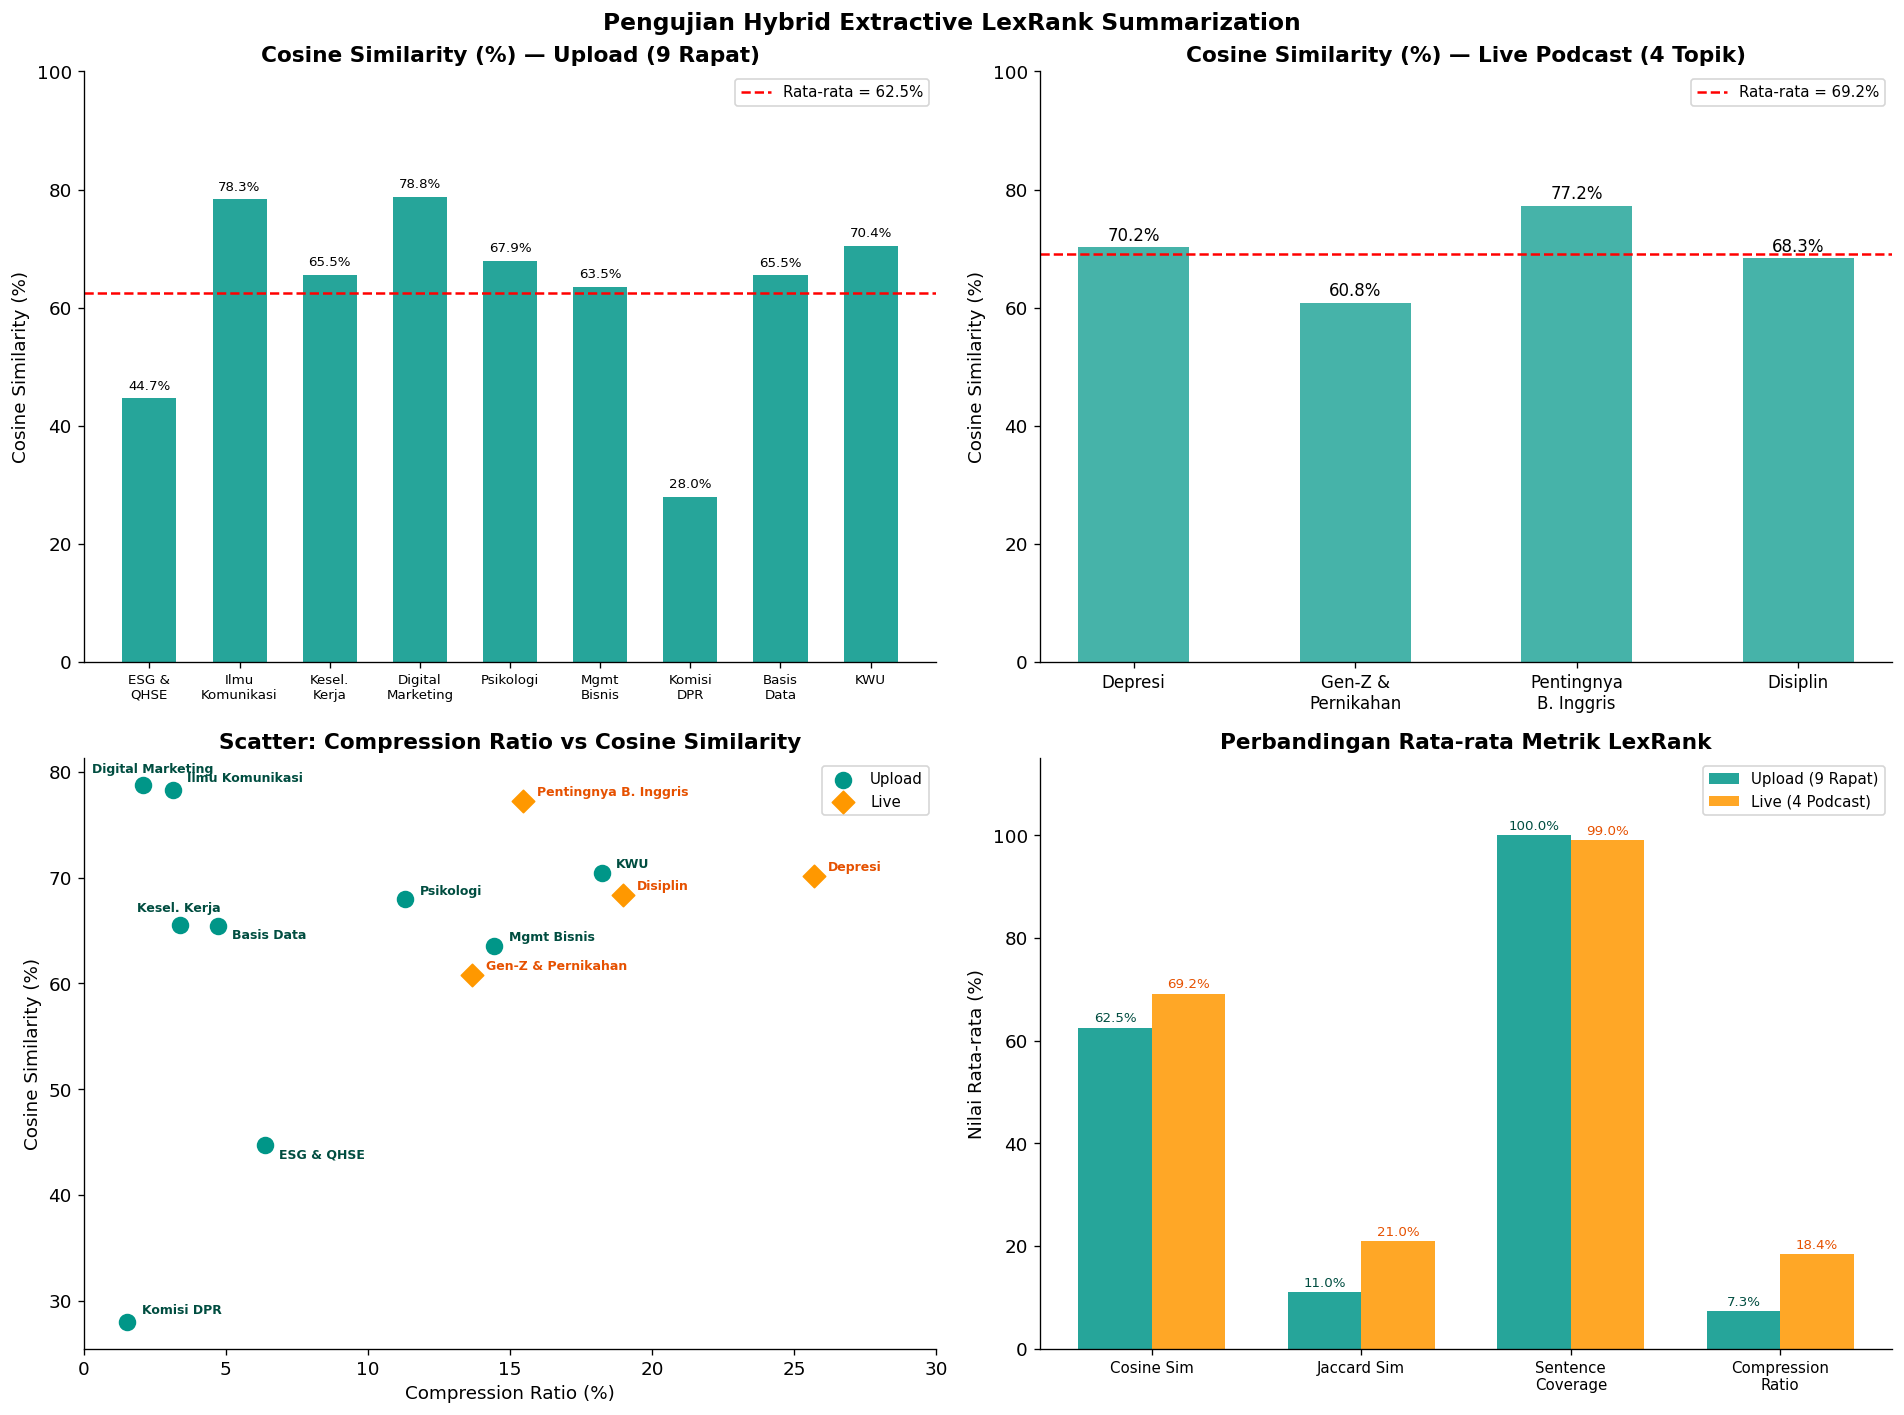


📌 RINGKASAN LEXRANK:
   Upload — Cosine Sim avg   : 62.52%
   Live   — Cosine Sim avg   : 69.15%
   Upload — Compression Ratio: 7.25%
   Live   — Compression Ratio: 18.44%


In [7]:
# ── DATA: LexRank Upload (9 Rapat) ─────────────────────────────
topik_lx_up = [
    'ESG &\nQHSE', 'Ilmu\nKomunikasi', 'Kesel.\nKerja',
    'Digital\nMarketing', 'Psikologi', 'Mgmt\nBisnis',
    'Komisi\nDPR', 'Basis\nData', 'KWU'
]
cosine_up    = [44.67, 78.31, 65.55, 78.76, 67.94, 63.54, 27.99, 65.47, 70.44]
jaccard_up   = [9.32,  5.97,  5.45,  4.26, 16.17, 20.67,  2.33,  7.67, 27.11]
coverage_up  = [100, 100, 100, 100, 100, 100, 100, 100, 100]
compress_up  = [6.39, 3.15, 3.39, 2.08, 11.32, 14.45, 1.54, 4.72, 18.23]

# ── DATA: LexRank Live (4 Podcast) ─────────────────────────────
topik_lx_lv = ['Depresi', 'Gen-Z &\nPernikahan', 'Pentingnya\nB. Inggris', 'Disiplin']
cosine_lv   = [70.19, 60.83, 77.24, 68.34]
jaccard_lv  = [23.50, 17.81, 20.87, 21.87]
coverage_lv = [100, 100, 100, 96]
compress_lv = [25.68, 13.66, 15.44, 18.97]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Pengujian Hybrid Extractive LexRank Summarization',
             fontsize=14, fontweight='bold')

# Panel 1: Cosine Similarity
ax = axes[0][0]
x = np.arange(len(topik_lx_up))
bw = 0.35
ax.bar(x, cosine_up, 0.6, color=TEAL, alpha=0.85)
ax.axhline(np.mean(cosine_up), color='red', linestyle='--', linewidth=1.5,
           label=f'Rata-rata = {np.mean(cosine_up):.1f}%')
for i, v in enumerate(cosine_up):
    ax.text(i, v+1, f'{v:.1f}%', ha='center', va='bottom', fontsize=8)
ax.set_title('Cosine Similarity (%) — Upload (9 Rapat)')
ax.set_xticks(x)
ax.set_xticklabels(topik_lx_up, fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel('Cosine Similarity (%)')
ax.legend(fontsize=9)

# Panel 2: Cosine Live
ax2 = axes[0][1]
x2 = np.arange(len(topik_lx_lv))
ax2.bar(x2, cosine_lv, 0.5, color='#26A69A', alpha=0.85)
ax2.axhline(np.mean(cosine_lv), color='red', linestyle='--', linewidth=1.5,
            label=f'Rata-rata = {np.mean(cosine_lv):.1f}%')
for i, v in enumerate(cosine_lv):
    ax2.text(i, v+0.5, f'{v:.1f}%', ha='center', va='bottom', fontsize=10)
ax2.set_title('Cosine Similarity (%) — Live Podcast (4 Topik)')
ax2.set_xticks(x2)
ax2.set_xticklabels(topik_lx_lv, fontsize=10)
ax2.set_ylim(0, 100)
ax2.set_ylabel('Cosine Similarity (%)')
ax2.legend(fontsize=9)

# Panel 3: Scatter Cosine vs Jaccard
ax3 = axes[1][0]
sc1 = ax3.scatter(compress_up, cosine_up, s=90, color=TEAL, label='Upload', zorder=5)
sc2 = ax3.scatter(compress_lv, cosine_lv, s=90, color=ORANGE, marker='D', label='Live', zorder=5)

# Custom manual offsets to avoid overlaps
custom_offsets = {
    'Digital Marketing': (-1.8, 1.2),
    'Ilmu Komunikasi': (0.5, 0.8),
    'Kesel. Kerja': (-1.5, 1.2),
    'Basis Data': (0.5, -1.2),
    'ESG & QHSE': (0.5, -1.2),
    'Komisi DPR': (0.5, 0.8)
}

for i, t in enumerate(topik_lx_up):
    name = t.replace('\n',' ')
    dx, dy = custom_offsets.get(name, (0.5, 0.5))
    ax3.text(compress_up[i] + dx, cosine_up[i] + dy, name, fontsize=7.5, fontweight='bold', color='#004D40')

for i, t in enumerate(topik_lx_lv):
    name = t.replace('\n',' ')
    dx, dy = custom_offsets.get(name, (0.5, 0.5))
    ax3.text(compress_lv[i] + dx, cosine_lv[i] + dy, name, fontsize=7.5, fontweight='bold', color='#E65100')

ax3.set_xlabel('Compression Ratio (%)')
ax3.set_ylabel('Cosine Similarity (%)')
ax3.set_title('Scatter: Compression Ratio vs Cosine Similarity')
ax3.set_xlim(0, 30)  # Keep the layout tight and professional
ax3.legend(fontsize=9)

# Panel 4: Radar
ax4 = axes[1][1]
cats = ['Cosine Sim', 'Jaccard Sim', 'Sentence\nCoverage', 'Compression\nRatio']
upload_vals = [np.mean(cosine_up), np.mean(jaccard_up), np.mean(coverage_up), np.mean(compress_up)]
live_vals   = [np.mean(cosine_lv), np.mean(jaccard_lv), np.mean(coverage_lv), np.mean(compress_lv)]

df_radar = pd.DataFrame({'Metrik': cats, 'Upload': upload_vals, 'Live': live_vals})
x4 = np.arange(len(cats))
bw4 = 0.35
ax4.bar(x4 - bw4/2, upload_vals, bw4, label='Upload (9 Rapat)', color=TEAL, alpha=0.85)
ax4.bar(x4 + bw4/2, live_vals,   bw4, label='Live (4 Podcast)', color=ORANGE, alpha=0.85)
for i, (u, l) in enumerate(zip(upload_vals, live_vals)):
    ax4.text(i-bw4/2, u+0.5, f'{u:.1f}%', ha='center', va='bottom', fontsize=8, color='#004D40')
    ax4.text(i+bw4/2, l+0.5, f'{l:.1f}%', ha='center', va='bottom', fontsize=8, color='#E65100')
ax4.set_xticks(x4)
ax4.set_xticklabels(cats, fontsize=9)
ax4.set_ylim(0, 115)
ax4.set_ylabel('Nilai Rata-rata (%)')
ax4.set_title('Perbandingan Rata-rata Metrik LexRank')
ax4.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../visual uji/5_lexrank_summarization.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n📌 RINGKASAN LEXRANK:')
print(f'   Upload — Cosine Sim avg   : {np.mean(cosine_up):.2f}%')
print(f'   Live   — Cosine Sim avg   : {np.mean(cosine_lv):.2f}%')
print(f'   Upload — Compression Ratio: {np.mean(compress_up):.2f}%')
print(f'   Live   — Compression Ratio: {np.mean(compress_lv):.2f}%')


---
## 6️⃣ Pengujian Ollama Abstractive Summarization (BERTScore)

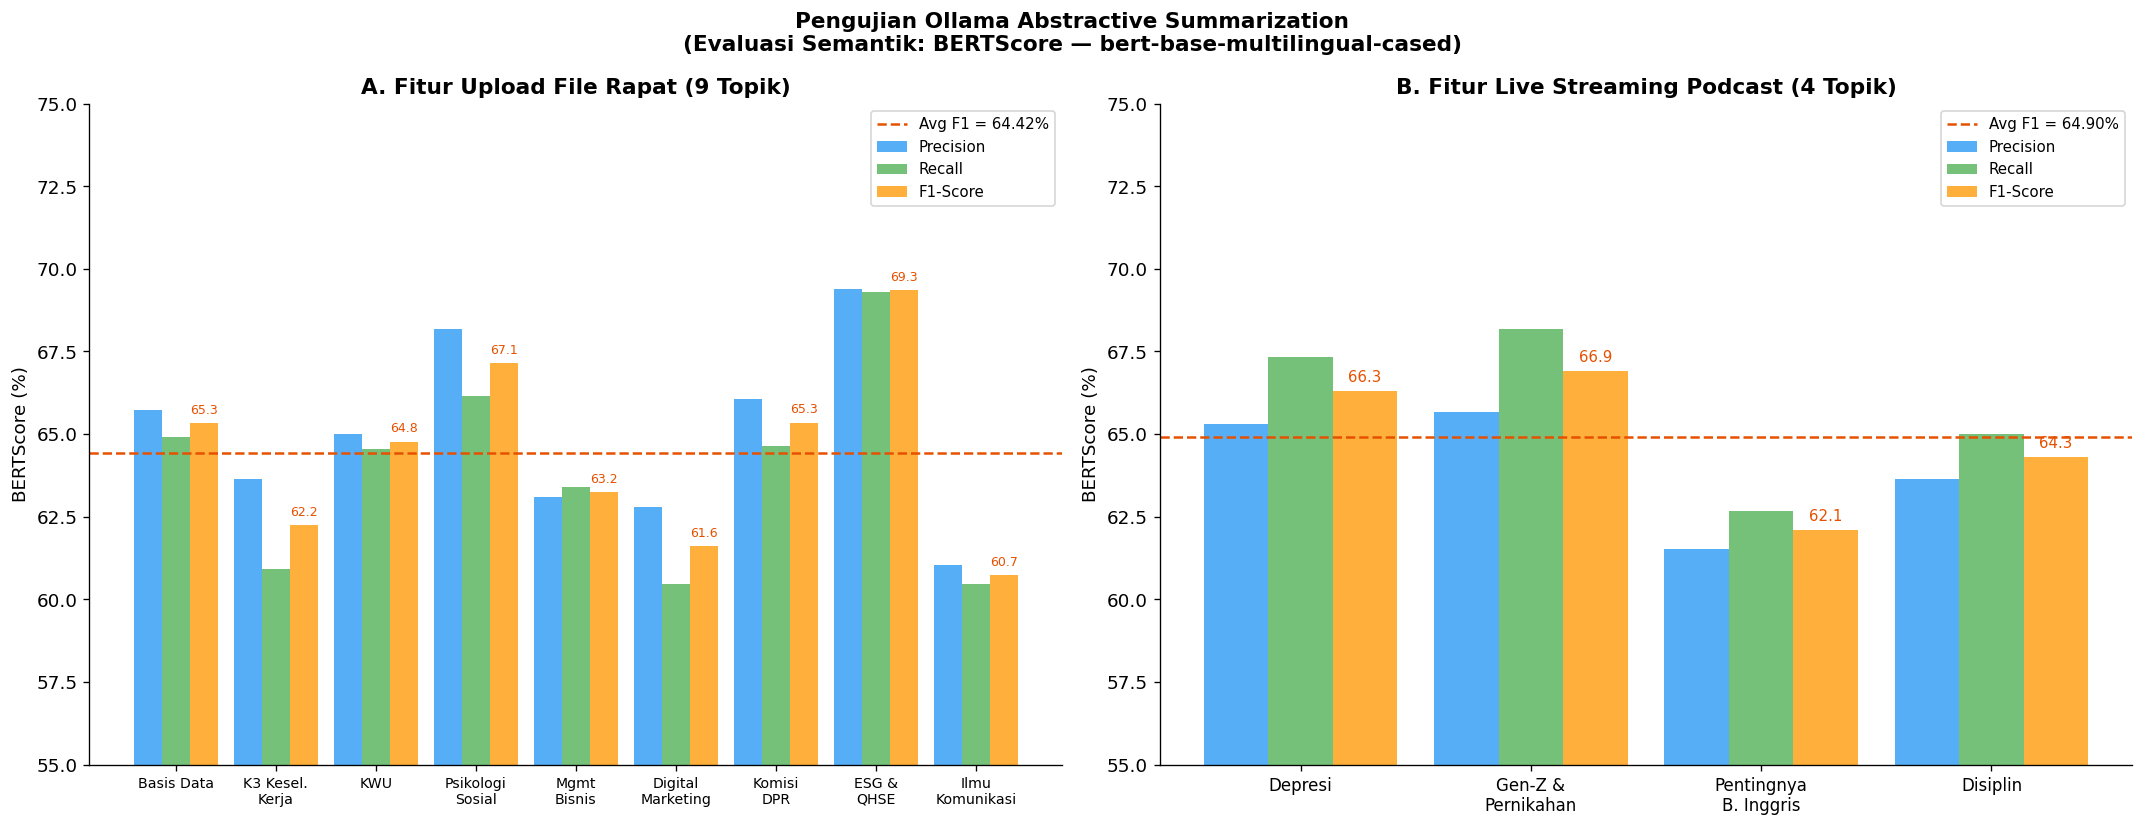


📌 RINGKASAN BERTSCORE OLLAMA:
   Upload — Rata-rata F1  : 64.42%
   Live   — Rata-rata F1  : 64.90%


In [8]:
# ── DATA: BERTScore Upload (9 Rapat) ───────────────────────────
topik_bert_up = [
    'Basis Data', 'K3 Kesel.\nKerja', 'KWU', 'Psikologi\nSosial',
    'Mgmt\nBisnis', 'Digital\nMarketing', 'Komisi\nDPR', 'ESG &\nQHSE', 'Ilmu\nKomunikasi'
]
bert_prec_up = [65.74, 63.64, 64.99, 68.18, 63.09, 62.79, 66.06, 69.39, 61.03]
bert_rec_up  = [64.91, 60.91, 64.55, 66.14, 63.41, 60.46, 64.65, 69.31, 60.46]
bert_f1_up   = [65.32, 62.25, 64.77, 67.14, 63.25, 61.60, 65.35, 69.35, 60.74]

# ── DATA: BERTScore Live (4 Podcast) ───────────────────────────
topik_bert_lv = ['Depresi', 'Gen-Z &\nPernikahan', 'Pentingnya\nB. Inggris', 'Disiplin']
bert_prec_lv  = [65.31, 65.67, 61.52, 63.64]
bert_rec_lv   = [67.34, 68.18, 62.67, 65.00]
bert_f1_lv    = [66.31, 66.90, 62.09, 64.31]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Pengujian Ollama Abstractive Summarization\n(Evaluasi Semantik: BERTScore — bert-base-multilingual-cased)',
             fontsize=13, fontweight='bold')

# --- Panel A: Upload ---
ax = axes[0]
x = np.arange(len(topik_bert_up))
bw = 0.28
ax.bar(x - bw, bert_prec_up, bw, label='Precision', color='#42A5F5', alpha=0.9)
ax.bar(x,      bert_rec_up,  bw, label='Recall',    color='#66BB6A', alpha=0.9)
ax.bar(x + bw, bert_f1_up,   bw, label='F1-Score',  color='#FFA726', alpha=0.9)
ax.axhline(np.mean(bert_f1_up), color='#E65100', linestyle='--', linewidth=1.5,
           label=f'Avg F1 = {np.mean(bert_f1_up):.2f}%')
ax.set_title('A. Fitur Upload File Rapat (9 Topik)')
ax.set_xticks(x)
ax.set_xticklabels(topik_bert_up, fontsize=8.5)
ax.set_ylim(55, 75)
ax.set_ylabel('BERTScore (%)')
ax.legend(fontsize=9)
for i, v in enumerate(bert_f1_up):
    ax.text(i+bw, v+0.2, f'{v:.1f}', ha='center', va='bottom', fontsize=7.5, color='#E65100')

# --- Panel B: Live ---
ax2 = axes[1]
x2 = np.arange(len(topik_bert_lv))
ax2.bar(x2 - bw, bert_prec_lv, bw, label='Precision', color='#42A5F5', alpha=0.9)
ax2.bar(x2,      bert_rec_lv,  bw, label='Recall',    color='#66BB6A', alpha=0.9)
ax2.bar(x2 + bw, bert_f1_lv,   bw, label='F1-Score',  color='#FFA726', alpha=0.9)
ax2.axhline(np.mean(bert_f1_lv), color='#E65100', linestyle='--', linewidth=1.5,
            label=f'Avg F1 = {np.mean(bert_f1_lv):.2f}%')
ax2.set_title('B. Fitur Live Streaming Podcast (4 Topik)')
ax2.set_xticks(x2)
ax2.set_xticklabels(topik_bert_lv, fontsize=10)
ax2.set_ylim(55, 75)
ax2.set_ylabel('BERTScore (%)')
ax2.legend(fontsize=9)
for i, v in enumerate(bert_f1_lv):
    ax2.text(i+bw, v+0.2, f'{v:.1f}', ha='center', va='bottom', fontsize=9, color='#E65100')

plt.tight_layout()
plt.savefig('../visual uji/6_bertscore_ollama.png', bbox_inches='tight', dpi=150)
plt.show()

print('\n📌 RINGKASAN BERTSCORE OLLAMA:')
print(f'   Upload — Rata-rata F1  : {np.mean(bert_f1_up):.2f}%')
print(f'   Live   — Rata-rata F1  : {np.mean(bert_f1_lv):.2f}%')

---
## 📈 Dashboard Ringkasan: Performance Model Keseluruhan

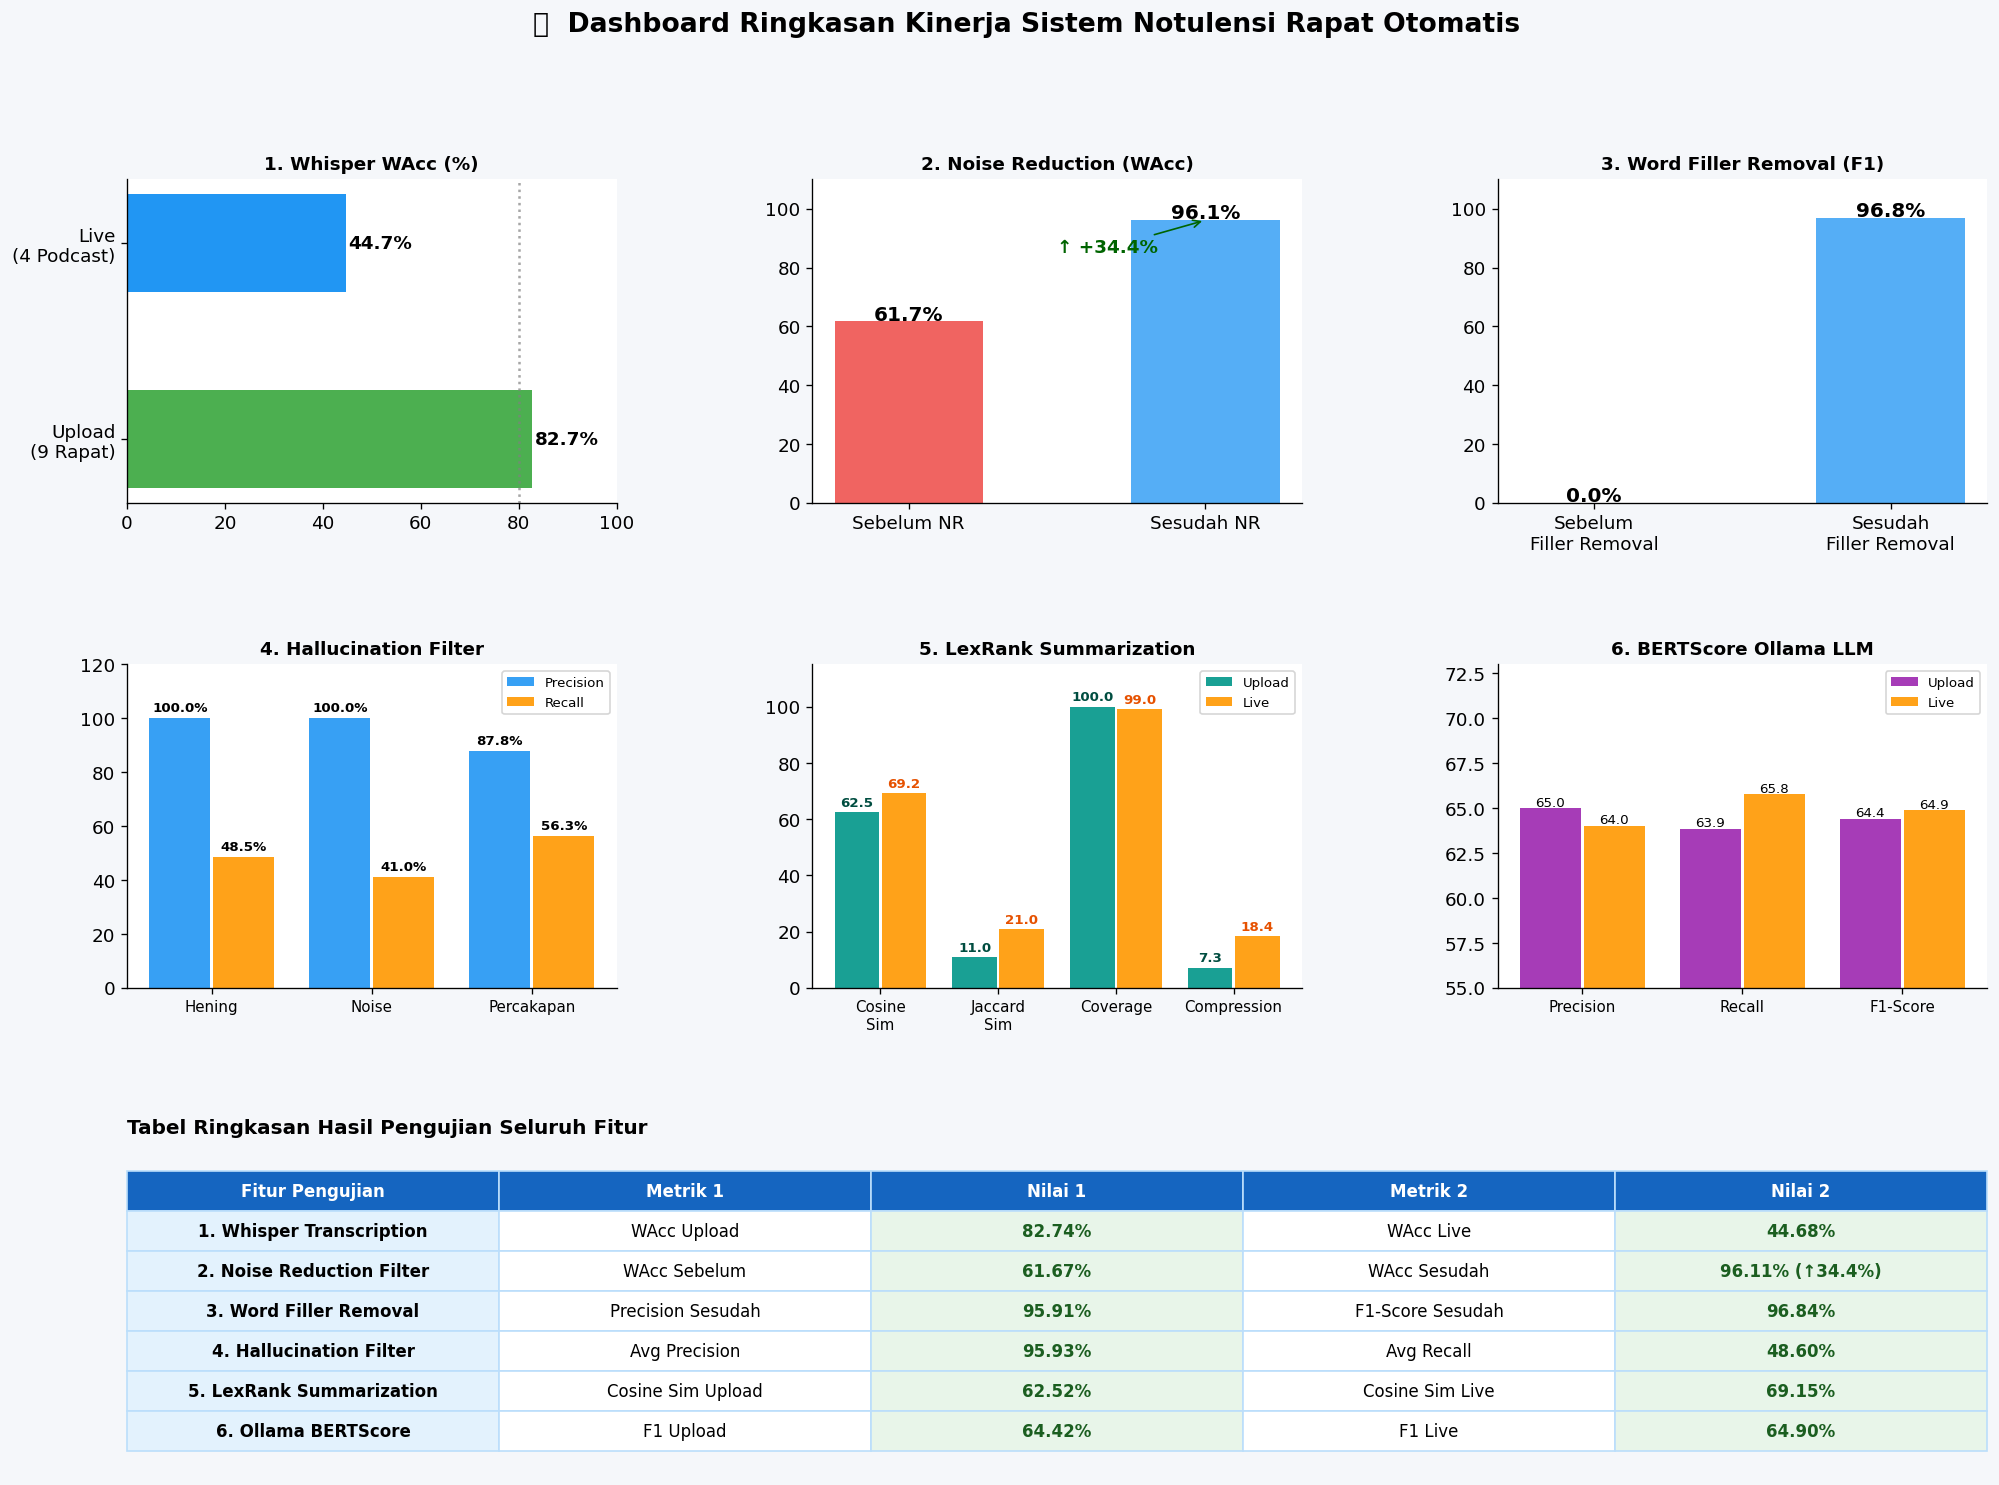


✅ Dashboard summary berhasil disimpan!


In [9]:
# ── DASHBOARD: Semua fitur dalam 1 ringkasan visual ────────────
fig = plt.figure(figsize=(20, 14))
fig.patch.set_facecolor('#F5F7FA')
fig.suptitle('📊  Dashboard Ringkasan Kinerja Sistem Notulensi Rapat Otomatis',
             fontsize=16, fontweight='bold', y=0.98)

gs = fig.add_gridspec(3, 3, hspace=0.5, wspace=0.4)

# --- 1. Whisper WAcc ---
ax1 = fig.add_subplot(gs[0, 0])
cats1 = ['Upload\n(9 Rapat)', 'Live\n(4 Podcast)']
vals1 = [np.mean(wacc_upload), np.mean(wacc_live)]
bars1 = ax1.barh(cats1, vals1, color=[GREEN, BLUE], height=0.5)
for bar, v in zip(bars1, vals1):
    ax1.text(v+0.5, bar.get_y()+bar.get_height()/2., f'{v:.1f}%',
             va='center', fontweight='bold', fontsize=11)
ax1.set_xlim(0, 100)
ax1.set_title('1. Whisper WAcc (%)', fontsize=11)
ax1.axvline(80, color='gray', linestyle=':', alpha=0.7)

# --- 2. Noise Reduction ---
ax2 = fig.add_subplot(gs[0, 1])
cats2 = ['Sebelum NR', 'Sesudah NR']
vals2 = [np.mean(wacc_before), np.mean(wacc_after)]
bars2 = ax2.bar(cats2, vals2, color=[BEFORE_COLOR, AFTER_COLOR], width=0.5, alpha=0.9)
for bar, v in zip(bars2, vals2):
    ax2.text(bar.get_x()+bar.get_width()/2., v+0.5, f'{v:.1f}%',
             ha='center', fontweight='bold', fontsize=12)
ax2.set_ylim(0, 110)
ax2.set_title('2. Noise Reduction (WAcc)', fontsize=11)
ax2.annotate(f'↑ +{np.mean(wacc_after)-np.mean(wacc_before):.1f}%',
             xy=(1, np.mean(wacc_after)), xytext=(0.5, 85),
             fontsize=11, color='darkgreen', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='darkgreen'))

# --- 3. Word Filler F1 ---
ax3 = fig.add_subplot(gs[0, 2])
cats3 = ['Sebelum\nFiller Removal', 'Sesudah\nFiller Removal']
vals3 = [0.0, np.mean(f1_after)]
colors3 = [BEFORE_COLOR, AFTER_COLOR]
bars3 = ax3.bar(cats3, vals3, color=colors3, width=0.5, alpha=0.9)
for bar, v in zip(bars3, vals3):
    ax3.text(bar.get_x()+bar.get_width()/2., v+0.5, f'{v:.1f}%',
             ha='center', fontweight='bold', fontsize=12)
ax3.set_ylim(0, 110)
ax3.set_title('3. Word Filler Removal (F1)', fontsize=11)

# --- 4. Hallucination Filter ---
ax4 = fig.add_subplot(gs[1, 0])
conds_h = ['Hening', 'Noise', 'Percakapan']
prec_short = [100.0, 100.0, 87.79]
rec_short  = [48.48, 40.97, 56.34]
x4v = np.arange(len(conds_h))
ax4.bar(x4v - 0.2, prec_short, 0.38, label='Precision', color=BLUE, alpha=0.9)
ax4.bar(x4v + 0.2, rec_short,  0.38, label='Recall',    color=ORANGE, alpha=0.9)
for j, (p, r) in enumerate(zip(prec_short, rec_short)):
    ax4.text(x4v[j]-0.2, p+1.5, f'{p:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
    ax4.text(x4v[j]+0.2, r+1.5, f'{r:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax4.set_xticks(x4v)
ax4.set_xticklabels(conds_h, fontsize=9)
ax4.set_ylim(0, 120)
ax4.set_title('4. Hallucination Filter', fontsize=11)
ax4.legend(fontsize=8)

# --- 5. LexRank ---
ax5 = fig.add_subplot(gs[1, 1])
cats5 = ['Cosine\nSim', 'Jaccard\nSim', 'Coverage', 'Compression']
up_avg = [np.mean(cosine_up), np.mean(jaccard_up), 100.0, np.mean(compress_up)]
lv_avg = [np.mean(cosine_lv), np.mean(jaccard_lv), np.mean(coverage_lv), np.mean(compress_lv)]
x5 = np.arange(len(cats5))
ax5.bar(x5 - 0.2, up_avg, 0.38, label='Upload', color=TEAL, alpha=0.9)
ax5.bar(x5 + 0.2, lv_avg, 0.38, label='Live',   color=ORANGE, alpha=0.9)
for j, (u, l) in enumerate(zip(up_avg, lv_avg)):
    ax5.text(x5[j]-0.2, u+1.0, f'{u:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#004D40')
    ax5.text(x5[j]+0.2, l+1.0, f'{l:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#E65100')
ax5.set_xticks(x5)
ax5.set_xticklabels(cats5, fontsize=9)
ax5.set_ylim(0, 115)
ax5.set_title('5. LexRank Summarization', fontsize=11)
ax5.legend(fontsize=8)

# --- 6. BERTScore ---
ax6 = fig.add_subplot(gs[1, 2])
cats6 = ['Precision', 'Recall', 'F1-Score']
up6 = [np.mean(bert_prec_up), np.mean(bert_rec_up), np.mean(bert_f1_up)]
lv6 = [np.mean(bert_prec_lv), np.mean(bert_rec_lv), np.mean(bert_f1_lv)]
x6 = np.arange(len(cats6))
ax6.bar(x6 - 0.2, up6, 0.38, label='Upload', color=PURPLE, alpha=0.9)
ax6.bar(x6 + 0.2, lv6, 0.38, label='Live',   color=ORANGE, alpha=0.9)
for i, (u,l) in enumerate(zip(up6,lv6)):
    ax6.text(i-0.2, u+0.1, f'{u:.1f}', ha='center', fontsize=8)
    ax6.text(i+0.2, l+0.1, f'{l:.1f}', ha='center', fontsize=8)
ax6.set_xticks(x6)
ax6.set_xticklabels(cats6, fontsize=9)
ax6.set_ylim(55, 73)
ax6.set_title('6. BERTScore Ollama LLM', fontsize=11)
ax6.legend(fontsize=8)

# --- Summary table row ---
ax7 = fig.add_subplot(gs[2, :])
ax7.axis('off')
summary_data = [
    ['1. Whisper Transcription', 'WAcc Upload', f'{np.mean(wacc_upload):.2f}%', 'WAcc Live', f'{np.mean(wacc_live):.2f}%'],
    ['2. Noise Reduction Filter', 'WAcc Sebelum', f'{np.mean(wacc_before):.2f}%', 'WAcc Sesudah', f'{np.mean(wacc_after):.2f}% (↑{np.mean(wacc_after)-np.mean(wacc_before):.1f}%)'],
    ['3. Word Filler Removal', 'Precision Sesudah', f'{np.mean(prec_after):.2f}%', 'F1-Score Sesudah', f'{np.mean(f1_after):.2f}%'],
    ['4. Hallucination Filter', 'Avg Precision', '95.93%', 'Avg Recall', '48.60%'],
    ['5. LexRank Summarization', 'Cosine Sim Upload', f'{np.mean(cosine_up):.2f}%', 'Cosine Sim Live', f'{np.mean(cosine_lv):.2f}%'],
    ['6. Ollama BERTScore', 'F1 Upload', f'{np.mean(bert_f1_up):.2f}%', 'F1 Live', f'{np.mean(bert_f1_lv):.2f}%'],
]
col_labels = ['Fitur Pengujian', 'Metrik 1', 'Nilai 1', 'Metrik 2', 'Nilai 2']
tbl = ax7.table(cellText=summary_data, colLabels=col_labels,
                loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 2.0)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor('#1565C0')
        cell.set_text_props(color='white', fontweight='bold')
    elif col == 0:
        cell.set_facecolor('#E3F2FD')
        cell.set_text_props(fontweight='bold')
    elif col in [2, 4]:
        cell.set_facecolor('#E8F5E9')
        cell.set_text_props(color='#1B5E20', fontweight='bold')
    else:
        cell.set_facecolor('#FFFFFF')
    cell.set_edgecolor('#BBDEFB')

ax7.set_title('Tabel Ringkasan Hasil Pengujian Seluruh Fitur', fontsize=12,
              fontweight='bold', pad=10, loc='left')

plt.savefig('../visual uji/0_dashboard_summary.png', bbox_inches='tight', dpi=150,
            facecolor='#F5F7FA')
plt.show()
print('\n✅ Dashboard summary berhasil disimpan!')

---
## ✅ Daftar File yang Dihasilkan

| No | File | Isi |
|---|---|---|
| 0 | `0_dashboard_summary.png` | Dashboard ringkasan semua fitur |
| 1 | `1_whisper_accuracy.png` | WER/WAcc/CER per topik rapat |
| 2 | `2_noise_reduction.png` | Perbandingan sebelum & sesudah Noise Reduction |
| 2b | `2b_noise_radar.png` | Radar chart WAcc per kondisi noise |
| 3 | `3_word_filler_removal.png` | Confusion matrix & metrik Filler Removal |
| 4 | `4_hallucination_filter.png` | Performa Hallucination Filter per kondisi |
| 5 | `5_lexrank_summarization.png` | Cosine Sim, Jaccard, Coverage, Compression |
| 6 | `6_bertscore_ollama.png` | BERTScore Precision/Recall/F1 Ollama LLM |